# 01 — NumPy fluency, linear and logistic regression from scratch

**Goal:** write, without help, the formulas the 2026-09-30 diagnostic showed you could not write from memory: normal
equation, gradient-descent update, binary cross-entropy, softmax + cross-entropy gradient `p − y`, ridge.
**Time:** ~3 h, or a 1-hour test if you think you know it: clear every check without help and move on. **Level:** 1 / 5.

**How to work (same for every notebook in this folder)**
1. Read the docstring, write the shapes on paper, then code. **No Claude / Copilot writing the code** — Claude Code only
   for the hint ladder (hint → bigger hint → micro-example), and only after 15 min stuck.
2. Fill the `✍️ Predict` cells *before* running the cell after them, with a confidence tag.
3. Run the `check` cell. Green ✅ = done. A red ❌ tells you *what* is wrong, not how to fix it.
4. At the end, copy the debrief into `learning/LOG.md`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
np.set_printoptions(precision=4, suppress=True)

def check(cond, msg):
    assert cond, "❌ " + msg
    print("✅", msg)

def rel_err(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.linalg.norm(a - b) / max(1e-12, np.linalg.norm(a) + np.linalg.norm(b))

## Part 0 — Shape drills (30 min)

No Python loops in this part. Every function is 1–3 lines.

In [2]:
def standardize(X):
    """Column-wise z-score. X: (n, d) -> (n, d), each column mean 0, std 1 (population std, ddof=0)."""
    return (X - X.mean(axis=0)) / X.std(axis=0)

def pairwise_sq_dists(A, B):
    """Squared Euclidean distances. A: (n, d), B: (m, d) -> D: (n, m) with D[i, j] = ||A[i] - B[j]||^2.
    Hint: expand ||a - b||^2 and use broadcasting. This is the core of k-NN."""
    return (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T

def one_hot(y, C):
    """y: (n,) ints in [0, C) -> Y: (n, C) float with Y[i, y[i]] = 1."""
    Y = np.zeros((len(y), C)); Y[np.arange(len(y)), y] = 1.0
    return Y

def softmax(Z):
    """Row-wise softmax. Z: (n, C) -> P: (n, C). Must not overflow for Z = 1000."""
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances

X = rng.normal(3, 2, size=(50, 4)); A = rng.normal(size=(7, 5)); B = rng.normal(size=(9, 5))
check(np.allclose(standardize(X), StandardScaler().fit_transform(X)), "standardize matches StandardScaler")
check(np.allclose(pairwise_sq_dists(A, B), euclidean_distances(A, B) ** 2), "pairwise_sq_dists matches sklearn")
check(one_hot(np.array([2, 0, 1]), 3).tolist() == [[0, 0, 1], [1, 0, 0], [0, 1, 0]], "one_hot")
P = softmax(np.array([[1000.0, 1000.0, 1000.0], [0.0, 1.0, 2.0]]))
check(np.all(np.isfinite(P)) and np.allclose(P.sum(1), 1), "softmax is stable and rows sum to 1")
check(np.allclose(P[0], 1 / 3), "softmax of equal logits is uniform")

✅ standardize matches StandardScaler
✅ pairwise_sq_dists matches sklearn
✅ one_hot
✅ softmax is stable and rows sum to 1
✅ softmax of equal logits is uniform


## Part 1 — Linear regression

Data: `n = 200`, `d = 3` features plus a bias column of ones, so `X` is `(200, 4)`.

In [4]:
n, d = 200, 3
X_raw = rng.normal(size=(n, d))
X = np.hstack([np.ones((n, 1)), X_raw])            # (n, d+1)
w_true = np.array([1.0, 2.0, -3.0, 0.5])
y = X @ w_true + rng.normal(0, 0.5, size=n)        # (n,)

**✍️ Predict before running.** Shape of `X.T @ X`? Of `X @ X.T`? Which one do you invert in the normal equation, and why can't it be the other (think rank, n = 200)?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [5]:
def fit_normal_eq(X, y):
    """Least squares via the normal equation. Use np.linalg.solve, not np.linalg.inv. Returns w: (p,)."""
    return np.linalg.solve(X.T @ X, X.T @ y)

def mse(w, X, y):
    """Mean squared error (1/n) * ||Xw - y||^2."""
    r = X @ w - y
    return r @ r / len(y)

def mse_grad(w, X, y):
    """Gradient of mse with respect to w. Returns (p,). Derive it on paper first."""
    return 2 / len(y) * X.T @ (X @ w - y)

def num_grad(f, w, eps=1e-6):
    """Central-difference numerical gradient of scalar f at w. w can have ANY shape; returns same shape.
    Hint: loop over np.ndindex(w.shape); perturb a copy."""
    g = np.zeros_like(w, dtype=float)
    for idx in np.ndindex(w.shape):
        wp, wm = w.astype(float).copy(), w.astype(float).copy()
        wp[idx] += eps; wm[idx] -= eps
        g[idx] = (f(wp) - f(wm)) / (2 * eps)
    return g

In [6]:
from sklearn.linear_model import LinearRegression

w_ne = fit_normal_eq(X, y)
check(np.allclose(w_ne, LinearRegression(fit_intercept=False).fit(X, y).coef_), "normal equation matches sklearn")
w0 = rng.normal(size=4)
check(rel_err(mse_grad(w0, X, y), num_grad(lambda w: mse(w, X, y), w0)) < 1e-6, "analytic gradient matches numerical")

✅ normal equation matches sklearn
✅ analytic gradient matches numerical


In [7]:
def fit_gd(X, y, lr, n_steps, w0=None):
    """Plain full-batch gradient descent on mse. Returns (w, losses) with losses a list of length n_steps
    (loss BEFORE each update). Stop early (return what you have) if the loss becomes non-finite."""
    w = np.zeros(X.shape[1]) if w0 is None else w0.copy()
    losses = []
    for _ in range(n_steps):
        L = mse(w, X, y)
        losses.append(L)
        if not np.isfinite(L):
            break
        w = w - lr * mse_grad(w, X, y)
    return w, losses

In [8]:
w_gd, losses = fit_gd(X, y, lr=0.1, n_steps=500)
check(np.allclose(w_gd, w_ne, atol=1e-6), "GD converges to the normal-equation solution")
check(all(np.diff(losses) <= 1e-12), "loss never increases at lr=0.1")

✅ GD converges to the normal-equation solution
✅ loss never increases at lr=0.1


### When does gradient descent diverge?

For `mse`, the Hessian is constant: `H = (2/n) XᵀX`. GD on a quadratic converges iff `lr < 2 / λ_max(H)`.

**✍️ Predict before running.** Run `fit_gd` with lr in `[0.01, 0.1, 0.5, 1.0, 1.5]`. Which ones diverge? Write your guess, then compute the threshold below and check.

> Prediction:
>
> Confidence: [1] / [2] / [3]

lr_max = 0.919


✅ lr=0.01: diverged=False, as predicted by lr_max
✅ lr=0.1: diverged=False, as predicted by lr_max
✅ lr=0.5: diverged=False, as predicted by lr_max
✅ lr=1.0: diverged=True, as predicted by lr_max
✅ lr=1.5: diverged=True, as predicted by lr_max


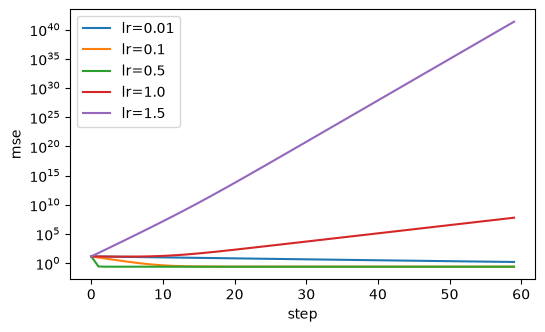

In [9]:
H = 2 / n * X.T @ X
lr_max = 2 / np.linalg.eigvalsh(H).max()
print(f"lr_max = {lr_max:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
for lr in [0.01, 0.1, 0.5, 1.0, 1.5]:
    _, L = fit_gd(X, y, lr, 60)
    ax.semilogy(L, label=f"lr={lr}")
    diverged = (not np.isfinite(L[-1])) or L[-1] > L[0]
    check(diverged == (lr > lr_max), f"lr={lr}: diverged={diverged}, as predicted by lr_max")
ax.set_xlabel("step"); ax.set_ylabel("mse"); ax.legend(); plt.show()

### Collinearity and ridge

Add a fourth feature that is an exact copy of the first one.

**✍️ Predict before running.** What happens to `X.T @ X` and to `fit_normal_eq`? What does ridge add that fixes it? As λ → ∞, what does `w_ridge` tend to?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [10]:
X_dup = np.hstack([X, X[:, [1]]])
print("rank:", np.linalg.matrix_rank(X_dup.T @ X_dup), "of", X_dup.shape[1], "| cond:", f"{np.linalg.cond(X_dup.T @ X_dup):.2e}")

def fit_ridge(X, y, lam):
    """argmin ||Xw - y||^2 + lam ||w||^2 (sum of squares, not mean). Closed form with np.linalg.solve."""
    return np.linalg.solve(X.T @ X + lam * np.eye(X.shape[1]), X.T @ y)

rank: 4 of 5 | cond: 3.34e+16


✅ ridge matches sklearn
✅ ridge splits the weight equally between the two copies
✅ ||w|| -> 0 as lambda grows


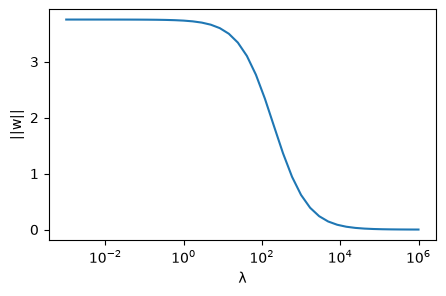

In [11]:
from sklearn.linear_model import Ridge

w_r = fit_ridge(X_dup, y, 1.0)
check(np.allclose(w_r, Ridge(alpha=1.0, fit_intercept=False).fit(X_dup, y).coef_), "ridge matches sklearn")
check(np.isclose(w_r[1], w_r[4]), "ridge splits the weight equally between the two copies")
lams = np.logspace(-3, 6, 40)
norms = [np.linalg.norm(fit_ridge(X, y, l)) for l in lams]
check(norms[-1] < 1e-2 * norms[0], "||w|| -> 0 as lambda grows")
plt.figure(figsize=(5, 3)); plt.semilogx(lams, norms); plt.xlabel("λ"); plt.ylabel("||w||"); plt.show()

Note: here the bias is penalised too. In practice you do **not** penalise the intercept — centre `y` and standardise `X`
instead. Write one sentence on why penalising the intercept is wrong (hint: shift every `y` by +100).

## Part 2 — Logistic regression

In [12]:
from sklearn.datasets import make_classification

Xc, yc = make_classification(n_samples=600, n_features=4, n_informative=3, n_redundant=0,
                             flip_y=0.1, class_sep=0.8, random_state=0)
Xc = np.hstack([np.ones((len(Xc), 1)), standardize(Xc)])   # (600, 5) with bias column

In [13]:
def sigmoid(z):
    """Numerically stable: no overflow warning for z = -1000 or +1000."""
    return np.exp(-np.logaddexp(0.0, -z))

def bce_loss(w, X, y):
    """Mean binary cross-entropy (Bernoulli negative log-likelihood) with logits z = Xw.
    Write it in terms of z, using np.logaddexp, so it never computes log(0)."""
    z = X @ w
    return np.mean(np.logaddexp(0.0, z) - y * z)

def bce_grad(w, X, y):
    """Gradient of bce_loss. Returns (p,)."""
    return X.T @ (sigmoid(X @ w) - y) / len(y)

def bce_hess(w, X, y):
    """Hessian of bce_loss. Returns (p, p). Hint: d/dz sigmoid(z) = s(1-s)."""
    s = sigmoid(X @ w)
    return (X * (s * (1 - s))[:, None]).T @ X / len(y)

In [14]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    s = sigmoid(np.array([-1000.0, 0.0, 1000.0]))
check(np.allclose(s, [0, 0.5, 1]), "sigmoid is stable")
w0 = rng.normal(size=5)
check(rel_err(bce_grad(w0, Xc, yc), num_grad(lambda w: bce_loss(w, Xc, yc), w0)) < 1e-6, "bce_grad matches numerical")
H_num = np.stack([num_grad(lambda w: bce_grad(w, Xc, yc)[j], w0) for j in range(5)])
check(rel_err(bce_hess(w0, Xc, yc), H_num) < 1e-5, "bce_hess matches numerical Jacobian of the gradient")
check(np.isclose(bce_loss(np.zeros(5), Xc, yc), np.log(2)), "loss at w = 0 is log 2")

✅ sigmoid is stable
✅ bce_grad matches numerical
✅ bce_hess matches numerical Jacobian of the gradient
✅ loss at w = 0 is log 2


**✍️ Predict before running.** Why is the loss at `w = 0` exactly `log 2`, whatever the data?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [15]:
def fit_logreg_newton(X, y, n_steps=20):
    """Newton's method: w <- w - H^{-1} g. Returns (w, losses)."""
    w = np.zeros(X.shape[1]); losses = []
    for _ in range(n_steps):
        losses.append(bce_loss(w, X, y))
        w = w - np.linalg.solve(bce_hess(w, X, y), bce_grad(w, X, y))
    return w, losses

✅ Newton logistic regression matches sklearn


/home/claude/ml-journey/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


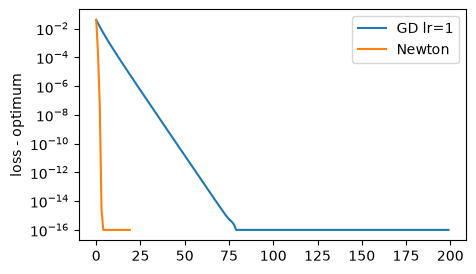

In [16]:
from sklearn.linear_model import LogisticRegression

w_nt, L_nt = fit_logreg_newton(Xc, yc)
w_sk = LogisticRegression(penalty=None, fit_intercept=False, tol=1e-10, max_iter=10_000).fit(Xc, yc).coef_[0]
check(np.allclose(w_nt, w_sk, atol=1e-4), "Newton logistic regression matches sklearn")

w = np.zeros(5); L_gd = []
for _ in range(200):
    L_gd.append(bce_loss(w, Xc, yc)); w -= 1.0 * bce_grad(w, Xc, yc)
plt.figure(figsize=(5, 3)); plt.semilogy(np.array(L_gd) - L_nt[-1] + 1e-16, label="GD lr=1")
plt.semilogy(np.array(L_nt) - L_nt[-1] + 1e-16, label="Newton"); plt.ylabel("loss - optimum"); plt.legend(); plt.show()

Newton converges in a handful of steps because it uses curvature `h = s(1−s)`. Keep this in mind: in XGBoost, each
leaf value is exactly one Newton step, `w* = −G / (H + λ)`. Notebook 06 makes you build that.

## Part 3 — Softmax regression on handwritten digits

In [17]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

Xd, yd = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd / 16.0, yd, test_size=0.3, random_state=0, stratify=yd)
add_bias = lambda A: np.hstack([np.ones((len(A), 1)), A])
Xd_tr, Xd_te = add_bias(Xd_tr), add_bias(Xd_te)        # (n, 65)
C = 10

In [18]:
def ce_loss(W, X, y):
    """Mean cross-entropy of softmax(X @ W). W: (p, C), y: (n,) ints. Use a stable log-sum-exp."""
    Z = X @ W
    m = Z.max(1, keepdims=True)
    lse = (m + np.log(np.exp(Z - m).sum(1, keepdims=True)))[:, 0]
    return np.mean(lse - Z[np.arange(len(y)), y])

def ce_grad(W, X, y):
    """Gradient with respect to W, shape (p, C). You should find X^T (P - Y) / n."""
    return X.T @ (softmax(X @ W) - one_hot(y, W.shape[1])) / len(y)

**✍️ Predict before running.** Value of `ce_loss` at `W = 0` with 10 classes? Why?

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [19]:
check(np.isclose(ce_loss(np.zeros((65, C)), Xd_tr, yd_tr), np.log(C)), "initial loss is log C")
W0 = rng.normal(0, 0.1, size=(65, C)); idx = rng.choice(len(yd_tr), 50, replace=False)
check(rel_err(ce_grad(W0, Xd_tr[idx], yd_tr[idx]), num_grad(lambda W: ce_loss(W, Xd_tr[idx], yd_tr[idx]), W0)) < 1e-6,
      "ce_grad matches numerical gradient")

✅ initial loss is log C
✅ ce_grad matches numerical gradient


In [20]:
W = np.zeros((65, C))
for step in range(500):
    W -= 0.5 * ce_grad(W, Xd_tr, yd_tr)
acc = np.mean((Xd_te @ W).argmax(1) == yd_te)
print(f"test accuracy: {acc:.3f}")
check(acc > 0.93, "softmax regression > 93% test accuracy on digits")

test accuracy: 0.961
✅ softmax regression > 93% test accuracy on digits


## Debrief → `learning/LOG.md`

Write, without looking back at the notebook:
1. The normal equation with shapes, and the condition for `XᵀX` to be invertible.
2. The GD update, and the learning-rate threshold for a quadratic loss.
3. BCE in terms of logits, its gradient, and why the softmax + CE gradient is `P − Y`.
4. **Still shaky:** every check you needed more than two attempts for, and every prediction tagged [2]/[3] that was wrong.